# Project 4: Customer Segmentation
 
This notebook builds an end-to-end **unsupervised learning** workflow that groups mall customers into segments according to their age, annual income and spending behaviour.
 
**Workflow:** data loading, cleaning, exploratory analysis, scaling, choosing the number of clusters, comparison of three clustering algorithms, stability check, segment profiling, model saving and assignment of new customers.

## 1. Project Introduction
 
Marketing works better when it is aimed at groups of similar customers rather than at everyone at once. The Mall Customers dataset describes 200 customers of a shopping mall: an identifier, gender, age, annual income (in thousands of dollars) and a spending score from 1 to 100 assigned by the mall based on purchasing behaviour.

## 2. Problem Statement
 
Group customers into a small number of segments that are internally similar and different from each other, and describe each segment in business terms.
 
- **Type:** unsupervised learning, clustering. There is no target column and no ground truth, so there is no accuracy score.
- **Algorithms compared:** K-Means, Agglomerative clustering (Ward linkage) and Gaussian Mixture Model
- **Metrics:** silhouette score, Davies-Bouldin index and Calinski-Harabasz index. The number of clusters is chosen with the silhouette score, and the choice is checked for stability across random starts and subsamples.

In [1]:
import json
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from features import (
    CLUSTER_FEATURES,
    ID_COLUMN,
    MAX_SEGMENTS,
    MIN_SEGMENTS,
    describe_segment,
    standardize_columns,
)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True

## 3. Dataset Loading
 
The dataset is read directly from a public GitHub raw URL. No manual download is needed.

In [2]:
DATA_URLS = [
    "https://raw.githubusercontent.com/SteffiPeTaffy/machineLearningAZ/master/Machine%20Learning%20A-Z%20Template%20Folder/Part%204%20-%20Clustering/Section%2024%20-%20K-Means%20Clustering/Mall_Customers.csv",
]


def load_dataset(urls, **read_options):
    last_error = None
    for url in urls:
        try:
            return pd.read_csv(url, **read_options)
        except Exception as error:
            last_error = error
    raise RuntimeError(f"None of the dataset URLs could be loaded: {urls}") from last_error


customers_raw = load_dataset(DATA_URLS)
customers = standardize_columns(customers_raw)
print(f"Rows: {customers.shape[0]:,}  Columns: {customers.shape[1]}")
customers.head()

Rows: 200  Columns: 5


,CustomerID,Gender,Age,AnnualIncome,SpendingScore
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## 4. Data Overview

In [3]:
customers.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   CustomerID     200 non-null    int64
 1   Gender         200 non-null    str  
 2   Age            200 non-null    int64
 3   AnnualIncome   200 non-null    int64
 4   SpendingScore  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB


In [4]:
customers.describe().T

,count,mean,std,min,25%,50%,75%,max
CustomerID,200.0,100.50,57.879185,1.0,50.75,100.5,150.25,200.0
Age,200.0,38.85,13.969007,18.0,28.75,36.0,49.00,70.0
AnnualIncome,200.0,60.56,26.264721,15.0,41.50,61.5,78.00,137.0
SpendingScore,200.0,50.20,25.823522,1.0,34.75,50.0,73.00,99.0


In [5]:
print(f"Duplicate rows: {customers.duplicated().sum()}")
print(f"Duplicate customer IDs: {customers[ID_COLUMN].duplicated().sum()}")
print(f"Missing values: {int(customers.isna().sum().sum())}")
customers["Gender"].value_counts().to_frame("customers")

Duplicate rows: 0
Duplicate customer IDs: 0
Missing values: 0


,customers
Gender,
Female,112
Male,88


## 5. Data Cleaning
 
Cleaning steps:
 
1. Remove duplicate rows and duplicate customer IDs.
2. Drop rows with missing values in the clustering features.
3. Keep `CustomerID` only as an identifier. It is not used for clustering.
 
`Gender` is **not** used for clustering. It is kept for profiling the segments afterwards, so that segments are defined by behaviour and not by a demographic label.

In [6]:
customers_clean = (
    customers.drop_duplicates()
    .drop_duplicates(subset=ID_COLUMN)
    .dropna(subset=CLUSTER_FEATURES)
    .reset_index(drop=True)
)
print(f"Rows before cleaning: {len(customers):,}")
print(f"Rows after cleaning:  {len(customers_clean):,}")
feature_frame = customers_clean[CLUSTER_FEATURES].astype(float)
feature_frame.describe().T.round(2)

Rows before cleaning: 200
Rows after cleaning:  200


,count,mean,std,min,25%,50%,75%,max
Age,200.0,38.85,13.97,18.0,28.75,36.0,49.0,70.0
AnnualIncome,200.0,60.56,26.26,15.0,41.50,61.5,78.0,137.0
SpendingScore,200.0,50.20,25.82,1.0,34.75,50.0,73.0,99.0


## 6. Exploratory Data Analysis

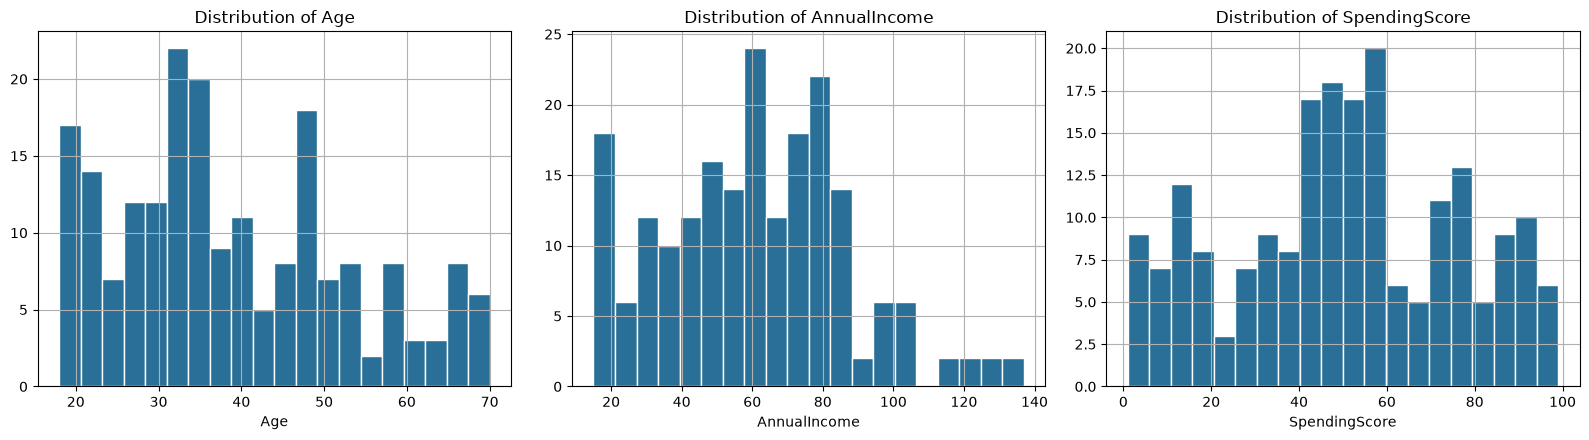

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for axis, column in zip(axes, CLUSTER_FEATURES):
    axis.hist(feature_frame[column], bins=20, color="#2a6f97", edgecolor="white")
    axis.set_title(f"Distribution of {column}")
    axis.set_xlabel(column)
plt.tight_layout()
plt.show()

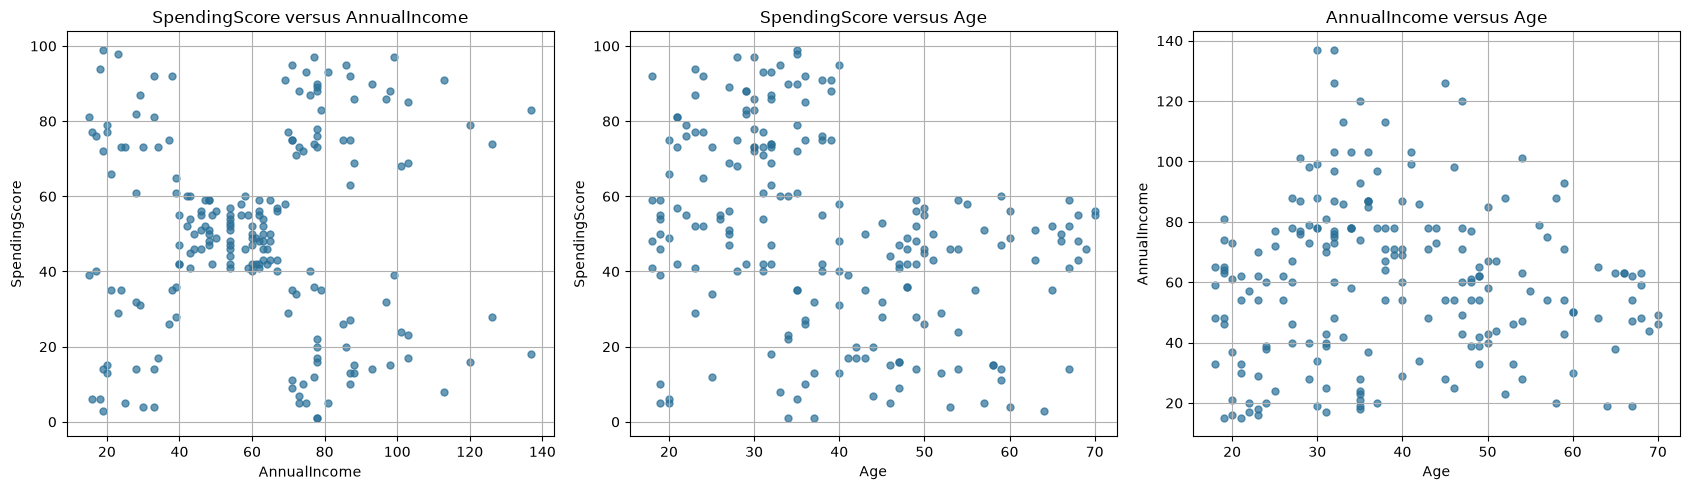

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
pairs = [("AnnualIncome", "SpendingScore"), ("Age", "SpendingScore"), ("Age", "AnnualIncome")]
for axis, (x_column, y_column) in zip(axes, pairs):
    axis.scatter(feature_frame[x_column], feature_frame[y_column], s=25, alpha=0.7, color="#2a6f97")
    axis.set_xlabel(x_column)
    axis.set_ylabel(y_column)
    axis.set_title(f"{y_column} versus {x_column}")
plt.tight_layout()
plt.show()

Average values by gender (not used for clustering):
         Age  AnnualIncome  SpendingScore  customers
Gender                                              
Female  38.1          59.2           51.5        112
Male    39.8          62.2           48.5         88


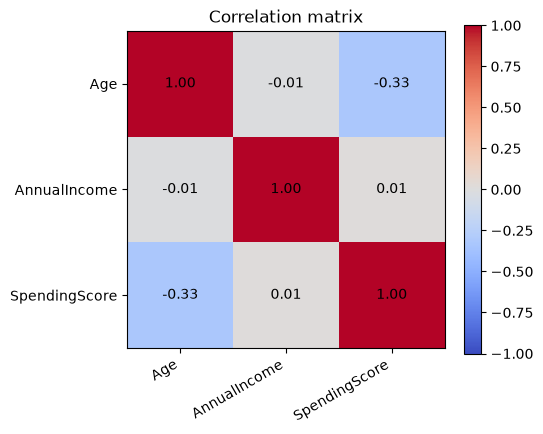

In [9]:
gender_summary = customers_clean.groupby("Gender")[CLUSTER_FEATURES].mean().round(1)
gender_summary["customers"] = customers_clean["Gender"].value_counts()
print("Average values by gender (not used for clustering):")
print(gender_summary)

correlations = feature_frame.corr()
fig, ax = plt.subplots(figsize=(5.5, 4.5))
image = ax.imshow(correlations, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlations.columns)))
ax.set_yticks(range(len(correlations.columns)))
ax.set_xticklabels(correlations.columns, rotation=30, ha="right")
ax.set_yticklabels(correlations.columns)
for row_index in range(len(correlations)):
    for column_index in range(len(correlations)):
        ax.text(column_index, row_index, f"{correlations.iloc[row_index, column_index]:.2f}", ha="center", va="center")
ax.grid(False)
fig.colorbar(image)
ax.set_title("Correlation matrix")
plt.tight_layout()
plt.show()

## 7. Data Preprocessing
 
K-Means and Agglomerative clustering are based on distances, so features with larger numeric ranges would dominate. Every feature is standardised to zero mean and unit variance.
 
There is no train/test split in this project because there is no target to predict. Instead the quality of the result is judged with internal metrics and a stability check later on.

In [10]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(feature_frame)
print("Scaled feature means:", X_scaled.mean(axis=0).round(3))
print("Scaled feature std:  ", X_scaled.std(axis=0).round(3))

Scaled feature means: [-0. -0. -0.]
Scaled feature std:   [1. 1. 1.]


## 8. Feature Engineering
 
The three behavioural features (`Age`, `AnnualIncome`, `SpendingScore`) are already meaningful and low-dimensional, so no new features are created. A two-dimensional PCA projection is computed later for visualisation only, not for modelling.

In [11]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_projected = pca.fit_transform(X_scaled)
print("Explained variance ratio of the two PCA components:", pca.explained_variance_ratio_.round(3))

Explained variance ratio of the two PCA components: [0.443 0.333]


## 9. Model Training: choosing the number of clusters
 
K-Means is fitted for every candidate number of clusters. Four diagnostics are compared: inertia (elbow method), silhouette score (higher is better), Davies-Bouldin index (lower is better) and Calinski-Harabasz index (higher is better).

In [12]:
k_values = list(range(2, MAX_SEGMENTS + 1))
k_rows = []
for k in k_values:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    k_rows.append(
        {
            "k": k,
            "inertia": kmeans.inertia_,
            "silhouette": silhouette_score(X_scaled, kmeans.labels_),
            "davies_bouldin": davies_bouldin_score(X_scaled, kmeans.labels_),
            "calinski_harabasz": calinski_harabasz_score(X_scaled, kmeans.labels_),
        }
    )
k_table = pd.DataFrame(k_rows).set_index("k")
k_table.round(4)

,inertia,silhouette,davies_bouldin,calinski_harabasz
k,,,,
2,389.3862,0.3355,1.2607,107.0956
3,295.2122,0.3578,1.0503,101.6949
4,205.2251,0.4040,0.9308,125.6764
5,168.2476,0.4166,0.8746,125.1009
6,133.8684,0.4284,0.8254,135.1021
7,117.0116,0.4172,0.7935,132.7743
8,103.8733,0.4082,0.8918,131.0062
9,93.0929,0.4177,0.8198,130.0036
10,82.3852,0.4066,0.8679,132.6383


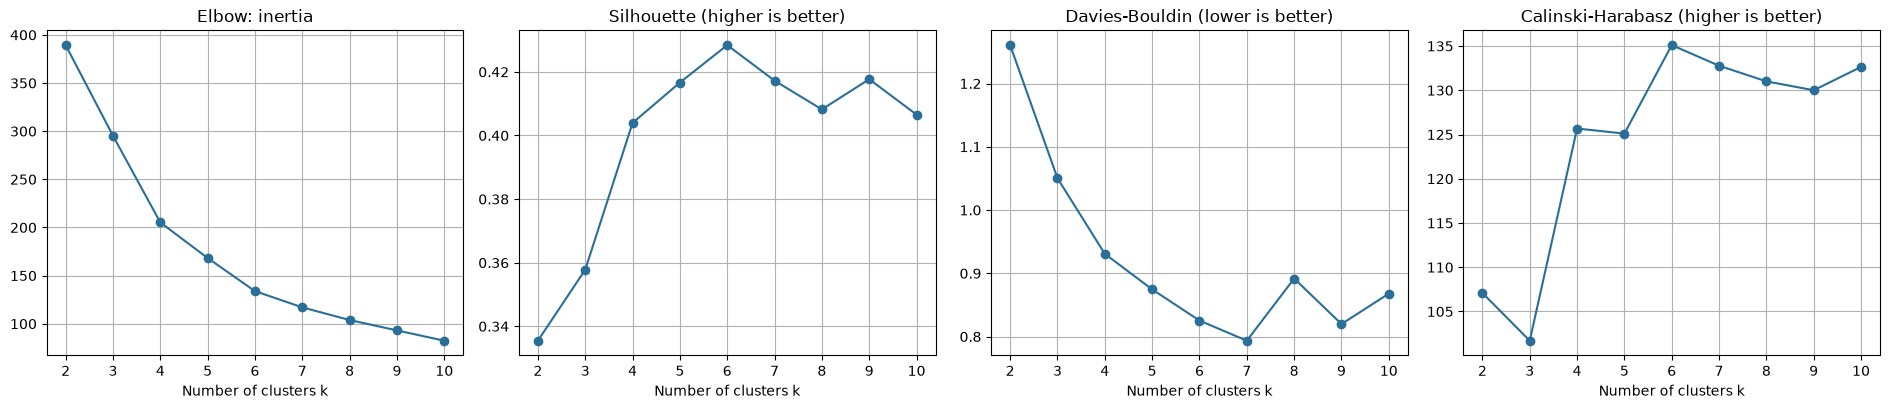

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(19, 4.2))
for axis, (column, title) in zip(
    axes,
    [
        ("inertia", "Elbow: inertia"),
        ("silhouette", "Silhouette (higher is better)"),
        ("davies_bouldin", "Davies-Bouldin (lower is better)"),
        ("calinski_harabasz", "Calinski-Harabasz (higher is better)"),
    ],
):
    axis.plot(k_table.index, k_table[column], marker="o", color="#2a6f97")
    axis.set_title(title)
    axis.set_xlabel("Number of clusters k")
plt.tight_layout()
plt.show()

## 10. Model Comparison
 
The number of segments is the k with the highest silhouette score among values of at least `MIN_SEGMENTS` (a split into only two groups is rarely useful for marketing). Three algorithm families are then compared at that k.

In [14]:
eligible = k_table[k_table.index >= MIN_SEGMENTS]
best_k = int(eligible["silhouette"].idxmax())
print(f"Selected number of segments (highest silhouette, k >= {MIN_SEGMENTS}): {best_k}")

algorithms = {
    "K-Means": KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE),
    "Agglomerative (Ward)": AgglomerativeClustering(n_clusters=best_k, linkage="ward"),
    "Gaussian Mixture": GaussianMixture(n_components=best_k, n_init=5, random_state=RANDOM_STATE),
}
algorithm_labels = {name: model.fit_predict(X_scaled) for name, model in algorithms.items()}
comparison_rows = []
for name, labels in algorithm_labels.items():
    comparison_rows.append(
        {
            "algorithm": name,
            "silhouette": silhouette_score(X_scaled, labels),
            "davies_bouldin": davies_bouldin_score(X_scaled, labels),
            "calinski_harabasz": calinski_harabasz_score(X_scaled, labels),
            "smallest_cluster_share": np.bincount(labels).min() / len(labels),
        }
    )
comparison_table = pd.DataFrame(comparison_rows).set_index("algorithm")
comparison_table.round(4)

Selected number of segments (highest silhouette, k >= 3): 6


,silhouette,davies_bouldin,calinski_harabasz,smallest_cluster_share
algorithm,,,,
K-Means,0.4284,0.8254,135.1021,0.105
Agglomerative (Ward),0.4201,0.8521,127.9865,0.105
Gaussian Mixture,0.3767,0.8713,107.5909,0.065


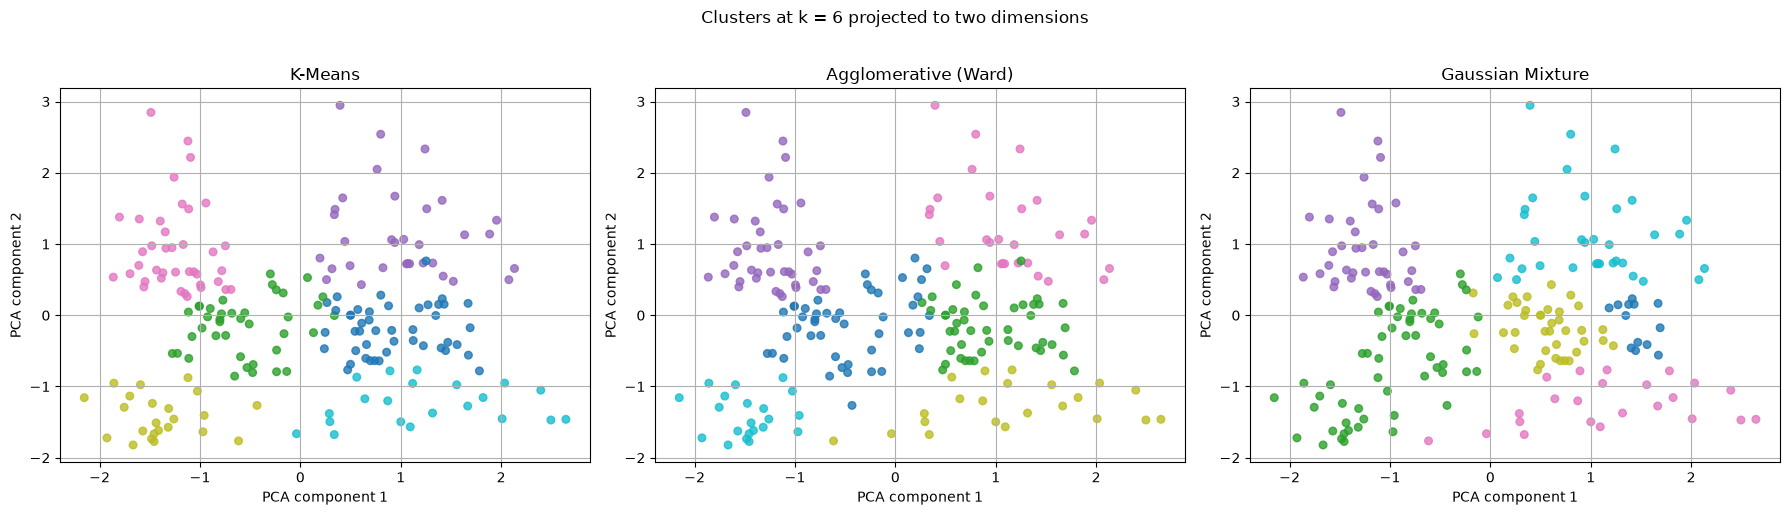

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for axis, (name, labels) in zip(axes, algorithm_labels.items()):
    scatter = axis.scatter(X_projected[:, 0], X_projected[:, 1], c=labels, cmap="tab10", s=30, alpha=0.8)
    axis.set_title(name)
    axis.set_xlabel("PCA component 1")
    axis.set_ylabel("PCA component 2")
plt.suptitle(f"Clusters at k = {best_k} projected to two dimensions", y=1.02)
plt.tight_layout()
plt.show()

## 11. Model Evaluation: stability
 
Without ground truth, a good clustering should at least be **stable**. Two checks are run with the adjusted Rand index (ARI), where 1 means identical groupings:
 
1. K-Means with many different random initialisations compared with the reference solution.
2. K-Means fitted on random 80% subsamples, then used to assign all customers, compared with the reference solution.

In [16]:
reference_labels = algorithm_labels["K-Means"]

seed_scores = [
    adjusted_rand_score(
        reference_labels,
        KMeans(n_clusters=best_k, n_init=1, random_state=seed).fit_predict(X_scaled),
    )
    for seed in range(20)
]

rng = np.random.default_rng(RANDOM_STATE)
subsample_scores = []
for _ in range(20):
    chosen = rng.choice(len(X_scaled), size=int(0.8 * len(X_scaled)), replace=False)
    sub_model = KMeans(n_clusters=best_k, n_init=10, random_state=int(rng.integers(1_000_000))).fit(X_scaled[chosen])
    subsample_scores.append(adjusted_rand_score(reference_labels, sub_model.predict(X_scaled)))

stability = {
    "seed_ari_mean": float(np.mean(seed_scores)),
    "seed_ari_min": float(np.min(seed_scores)),
    "subsample_ari_mean": float(np.mean(subsample_scores)),
    "subsample_ari_min": float(np.min(subsample_scores)),
}
for name, value in stability.items():
    print(f"{name:<20}: {value:.3f}")

seed_ari_mean       : 0.873
seed_ari_min        : 0.651
subsample_ari_mean  : 0.963
subsample_ari_min   : 0.904


## 12. Best Model Selection
 
K-Means is used as the production model: it assigns new customers directly with `predict`, its centroids are easy to explain, and it can be saved together with the scaler in one pipeline. The comparison table above shows whether the other algorithms offered a clearly better grouping. The final pipeline is fitted on all customers.

In [17]:
segmentation_pipeline = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("kmeans", KMeans(n_clusters=best_k, n_init=20, random_state=RANDOM_STATE)),
    ]
)
segmentation_pipeline.fit(feature_frame)
segment_labels = segmentation_pipeline.predict(feature_frame)
final_scaled = segmentation_pipeline.named_steps["scaler"].transform(feature_frame)
final_silhouette = float(silhouette_score(final_scaled, segment_labels))
print(f"Final model: K-Means with k = {best_k}")
print(f"Silhouette score: {final_silhouette:.4f}")
print("Customers per segment:")
print(pd.Series(segment_labels).value_counts().sort_index().to_string())

Final model: K-Means with k = 6
Silhouette score: 0.4274
Customers per segment:
0    33
1    45
2    24
3    39
4    38
5    21


### Segment profiles
 
Each segment is described by its average age, income and spending score, relative to the median customer. The labels High/Low and Older/Younger are computed from the data, not typed in by hand.

In [18]:
profiled = customers_clean.assign(segment=segment_labels)
profile = profiled.groupby("segment")[CLUSTER_FEATURES].mean().round(1)
profile["customers"] = profiled["segment"].value_counts().sort_index()
profile["share_percent"] = (profile["customers"] / len(profiled) * 100).round(1)
profile["female_percent"] = (profiled["Gender"].eq("Female").groupby(profiled["segment"]).mean() * 100).round(1)

medians = feature_frame.median().to_dict()
segment_levels = {
    int(segment): describe_segment(profile.loc[segment], medians) for segment in profile.index
}
segment_names = {
    segment: f"Segment {segment}: {levels['income']} income, {levels['spending']} spending, {levels['age'].lower()}"
    for segment, levels in segment_levels.items()
}
profile.insert(0, "name", [segment_names[int(segment)] for segment in profile.index])
profile

,name,Age,AnnualIncome,SpendingScore,customers,share_percent,female_percent
segment,,,,,,,
0,"Segment 0: High income, Low spending, older",41.9,88.9,17.0,33,16.5,42.4
1,"Segment 1: Low income, Low spending, older",56.3,54.3,49.1,45,22.5,57.8
2,"Segment 2: Low income, High spending, younger",25.2,25.8,76.9,24,12.0,58.3
3,"Segment 3: High income, High spending, younger",32.7,86.5,82.1,39,19.5,53.8
4,"Segment 4: Low income, Low spending, younger",26.7,57.6,47.8,38,19.0,63.2
5,"Segment 5: Low income, Low spending, older",45.5,26.3,19.4,21,10.5,61.9


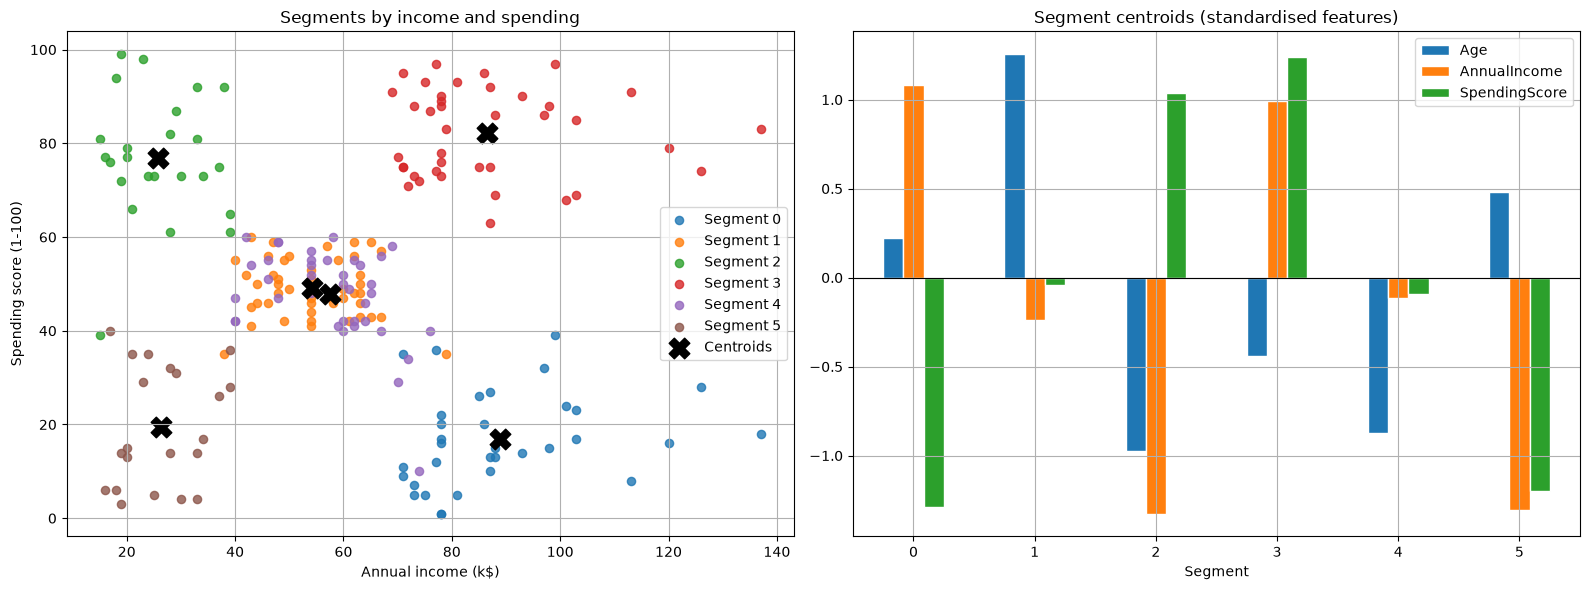

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for segment in sorted(segment_names):
    members = profiled[profiled["segment"] == segment]
    axes[0].scatter(members["AnnualIncome"], members["SpendingScore"], s=35, alpha=0.8, label=f"Segment {segment}")
centers = segmentation_pipeline.named_steps["scaler"].inverse_transform(segmentation_pipeline.named_steps["kmeans"].cluster_centers_)
center_frame = pd.DataFrame(centers, columns=CLUSTER_FEATURES)
axes[0].scatter(center_frame["AnnualIncome"], center_frame["SpendingScore"], marker="X", s=220, color="black", label="Centroids")
axes[0].set_xlabel("Annual income (k$)")
axes[0].set_ylabel("Spending score (1-100)")
axes[0].set_title("Segments by income and spending")
axes[0].legend()

standardized_centers = pd.DataFrame(segmentation_pipeline.named_steps["kmeans"].cluster_centers_, columns=CLUSTER_FEATURES)
standardized_centers.plot(kind="bar", ax=axes[1], edgecolor="white")
axes[1].set_title("Segment centroids (standardised features)")
axes[1].set_xlabel("Segment")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

## 13. Model Saving
 
The scaler and K-Means model are saved together as `model.pkl`. The file `metadata.json` stores the segment profiles, the evaluation tables, the stability scores and a copy of the customer points used by the Streamlit app.

In [20]:
def json_default(value):
    return value.item() if hasattr(value, "item") else str(value)


feature_ranges = {
    column: {
        "min": float(feature_frame[column].min()),
        "max": float(feature_frame[column].max()),
        "median": float(feature_frame[column].median()),
    }
    for column in CLUSTER_FEATURES
}
customer_points = profiled[CLUSTER_FEATURES + ["segment"]].round(2).to_dict(orient="records")

metadata = {
    "project": "Customer Segmentation",
    "algorithm": "K-Means",
    "n_segments": int(best_k),
    "features": CLUSTER_FEATURES,
    "silhouette": final_silhouette,
    "davies_bouldin": float(davies_bouldin_score(final_scaled, segment_labels)),
    "calinski_harabasz": float(calinski_harabasz_score(final_scaled, segment_labels)),
    "stability": stability,
    "feature_ranges": feature_ranges,
    "segment_names": {str(segment): name for segment, name in segment_names.items()},
    "segment_levels": {str(segment): levels for segment, levels in segment_levels.items()},
    "segment_profiles": profile.reset_index().to_dict(orient="records"),
    "k_selection": k_table.reset_index().to_dict(orient="records"),
    "algorithm_comparison": comparison_table.reset_index().to_dict(orient="records"),
    "customer_points": customer_points,
    "training_rows": int(len(feature_frame)),
}

joblib.dump(segmentation_pipeline, "model.pkl")
with open("metadata.json", "w", encoding="utf-8") as metadata_file:
    json.dump(metadata, metadata_file, indent=2, default=json_default)
print("Saved model.pkl and metadata.json")

Saved model.pkl and metadata.json


## 14. Prediction on New Data
 
The saved model is loaded from disk and assigns new customers to a segment. A customer can only be described by the same three features that were used for training.

In [21]:
loaded_model = joblib.load("model.pkl")

new_customers = pd.DataFrame(
    [
        {"Age": 23, "AnnualIncome": 20, "SpendingScore": 80},
        {"Age": 45, "AnnualIncome": 90, "SpendingScore": 15},
        {"Age": 32, "AnnualIncome": 85, "SpendingScore": 85},
        {"Age": 55, "AnnualIncome": 50, "SpendingScore": 50},
    ]
)[CLUSTER_FEATURES]

assigned = loaded_model.predict(new_customers)
new_customers["segment"] = assigned
new_customers["segment_name"] = [segment_names[int(segment)] for segment in assigned]
consistency_check = bool(np.array_equal(loaded_model.predict(feature_frame), segment_labels))
print(f"Loaded model reproduces the training assignments: {consistency_check}")
new_customers

Loaded model reproduces the training assignments: True


,Age,AnnualIncome,SpendingScore,segment,segment_name
0,23,20,80,2,"Segment 2: Low income, High spending, younger"
1,45,90,15,0,"Segment 0: High income, Low spending, older"
2,32,85,85,3,"Segment 3: High income, High spending, younger"
3,55,50,50,1,"Segment 1: Low income, Low spending, older"


## 15. Final Conclusion

In [22]:
print(f"Selected number of segments: {best_k} (silhouette {final_silhouette:.3f})")
print(f"Stability (mean ARI): random starts {stability['seed_ari_mean']:.3f}, subsamples {stability['subsample_ari_mean']:.3f}")
print()
print("Segments:")
for segment in sorted(segment_names):
    row = profile.loc[segment]
    print(
        f"  {segment_names[segment]} | {int(row['customers'])} customers ({row['share_percent']}%) | "
        f"age {row['Age']}, income {row['AnnualIncome']}k$, spending {row['SpendingScore']}"
    )
print()
print("Algorithm comparison (silhouette):")
print(comparison_table["silhouette"].sort_values(ascending=False).round(4).to_string())

Selected number of segments: 6 (silhouette 0.427)
Stability (mean ARI): random starts 0.873, subsamples 0.963

Segments:
  Segment 0: High income, Low spending, older | 33 customers (16.5%) | age 41.9, income 88.9k$, spending 17.0
  Segment 1: Low income, Low spending, older | 45 customers (22.5%) | age 56.3, income 54.3k$, spending 49.1
  Segment 2: Low income, High spending, younger | 24 customers (12.0%) | age 25.2, income 25.8k$, spending 76.9
  Segment 3: High income, High spending, younger | 39 customers (19.5%) | age 32.7, income 86.5k$, spending 82.1
  Segment 4: Low income, Low spending, younger | 38 customers (19.0%) | age 26.7, income 57.6k$, spending 47.8
  Segment 5: Low income, Low spending, older | 21 customers (10.5%) | age 45.5, income 26.3k$, spending 19.4

Algorithm comparison (silhouette):
algorithm
K-Means                 0.4284
Agglomerative (Ward)    0.4201
Gaussian Mixture        0.3767


**Summary of the approach**
 
- Features were standardised and the number of clusters was chosen with several internal metrics instead of the elbow plot alone.
- Three clustering algorithms were compared, and the chosen K-Means model was checked for stability across random starts and subsamples.
- Segments are described by data-driven labels, so each one can be turned into a specific marketing idea.
 
**Limitations and next steps**
 
- There is no ground truth, so metrics measure cluster shape and not business value. The best number of segments should also be judged by how usable the segments are.
- The dataset is small (about 200 customers) and the spending score is a score assigned by the mall, not raw transaction data.
- Possible improvements: add real purchase history (recency, frequency, monetary value), test other clustering methods such as DBSCAN, and re-run the segmentation regularly to monitor drift.